# CETSP results explorer

A single notebook for any results file and any subset of formulations.
Point `SOURCE` at the data, pick formulations with `select(...)`, and every
figure and table below follows.

Nothing is hard-coded to a particular formulation set, instance grid or time
limit: labels are parsed from the `BASE-A-D-cut-S-OC-B` grammar that
`run_experiment.py` builds, the radius regime is recovered from `r_min` and
`r_max`, and the time limit is inferred from the runs that hit it.

The API lives in [`utils/results.py`](utils/results.py) (loading, selection,
tables) and [`utils/plots.py`](utils/plots.py) (figures).

In [24]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

from utils.results import (coverage_report, describe_formulation,
                           formulations_in, load_results, missing_cells,
                           order_formulations, pairwise_table, select,
                           summary_table, METRICS)
from utils.plots import (coverage_heatmap, pairwise_scatter,
                         performance_profile, scaling_plot)

# Uneven coverage between formulations is reported as a warning rather than
# being silently aligned away, so make sure every occurrence is shown.
warnings.simplefilter('always', UserWarning)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
plt.rcParams['figure.dpi'] = 110

## 1. Load

`load_results` takes one `.csv` or `.xlsx` file. For a workbook it picks the
first sheet that carries the results columns, so pivot-table sheets are
skipped. A file written by an older run carries only nine columns; the rest
are filled with nulls, so both schemas load the same way.

In [25]:
SOURCE = 'aws-B-S.xlsx'

# Any other results file works the same way, e.g.
#   SOURCE = 'Results/experiment_results.csv'
# Name a sheet with load_results(SOURCE, sheet='...') if the default pick is
# not the one you want.

df = load_results(SOURCE)
print(f'{len(df)} runs from {df.attrs["source"]}')
df.head(3)

3368 runs from aws-B-S[awsABF+SB+n30]


,Formulation,n,r_min,r_max,Instance,Status,Gap,Time,UB,LB,Root Bound,Nodes,Cuts,DFJ_Cuts,Sub_Failures,r_mean,sigma,Solved,GapPct,TimeLimit,RootGapPct,base,cut,extended,decomposition,strengthen,opt_coeff,symmetry
0,ABF-A-D-S-B,10,0.2,0.3,0,Optimal,0.000000e+00,1.230937,24.300783,24.300783,18.781510,1428,83,5,0,0.25,0.2,True,0.000000e+00,1800.0,22.712324,ABF,None,True,True,True,False,True
1,ABF-A-D-S-B,10,0.2,0.3,1,Optimal,5.678781e-16,0.424595,25.024481,25.024481,20.502247,290,7,7,0,0.25,0.2,True,5.678781e-14,1800.0,18.071241,ABF,None,True,True,True,False,True
2,ABF-A-D-S-B,10,0.2,0.3,2,Optimal,1.758168e-16,0.479378,20.206904,20.206904,16.601438,406,11,9,0,0.25,0.2,True,1.758168e-14,1800.0,17.842745,ABF,None,True,True,True,False,True


## 2. What is in the file

Run this before any comparison: it is the fastest way to see which
formulations are present, how far the instance grid goes, and what is still
missing from a partial run.

In [26]:
print('Formulations :', len(formulations_in(df)))
for label in formulations_in(df):
    print(f'  {label:<24} {describe_formulation(label)}')

print('\nn            :', sorted(df['n'].unique()))
print('r_mean       :', sorted(df['r_mean'].unique()))
print('sigma        :', sorted(df['sigma'].unique()))
print('Status       :', dict(df['Status'].value_counts()))
print('\nTime limit inferred per size:')
print(df.groupby('n')['TimeLimit'].first())

Formulations : 15
  ABF-S-B                  ABF (DFJ strengthening, symmetry breaking)
  ABF-D-S-B                ABF (Benders, DFJ strengthening, symmetry breaking)
  ABF-A-S-B                ABF (polyhedral, DFJ strengthening, symmetry breaking)
  ABF-A-D-S-B              ABF (polyhedral, Benders, DFJ strengthening, symmetry breaking)
  SBF-B                    SBF (symmetry breaking)
  SBF-A-B                  SBF (polyhedral, symmetry breaking)
  SBF-A-D-enum-B           SBF (polyhedral, Benders, enumerative cuts, symmetry breaking)
  SBF-A-D-dual-B           SBF (polyhedral, Benders, dual cuts, symmetry breaking)
  PBF-S-B                  PBF (DFJ strengthening, symmetry breaking)
  PBF-D-enum-S-B           PBF (Benders, enumerative cuts, DFJ strengthening, symmetry breaking)
  PBF-D-dual-S-OC-B        PBF (Benders, dual cuts, DFJ strengthening, optimised coefficients, symmetry breaking)
  PBF-A-S-B                PBF (polyhedral, DFJ strengthening, symmetry breaking)
  PBF-A-D-

In [27]:
report = coverage_report(df)
print(f"instance cells in the grid: {report.attrs['cells']}")
display(report)

gaps = missing_cells(df)
if len(gaps):
    print(f'{len(gaps)} missing runs:')
    display(gaps)

instance cells in the grid: 225


,Formulation,Runs,Cells,Missing,Coverage (%)
0,ABF-S-B,225,225,0,100.000000
1,ABF-D-S-B,225,225,0,100.000000
2,ABF-A-S-B,225,225,0,100.000000
3,ABF-A-D-S-B,225,225,0,100.000000
4,SBF-B,218,218,7,96.888889
5,SBF-A-B,225,225,0,100.000000
6,SBF-A-D-enum-B,225,225,0,100.000000
7,SBF-A-D-dual-B,225,225,0,100.000000
8,PBF-S-B,225,225,0,100.000000
9,PBF-D-enum-S-B,225,225,0,100.000000


7 missing runs:


,n,r_min,r_max,Instance,Formulation
0,20,0.400,0.600,3,SBF-B
1,20,0.400,0.600,4,SBF-B
2,25,0.125,0.375,0,SBF-B
3,25,0.125,0.375,1,SBF-B
4,25,0.125,0.375,2,SBF-B
5,25,0.125,0.375,3,SBF-B
6,25,0.125,0.375,4,SBF-B


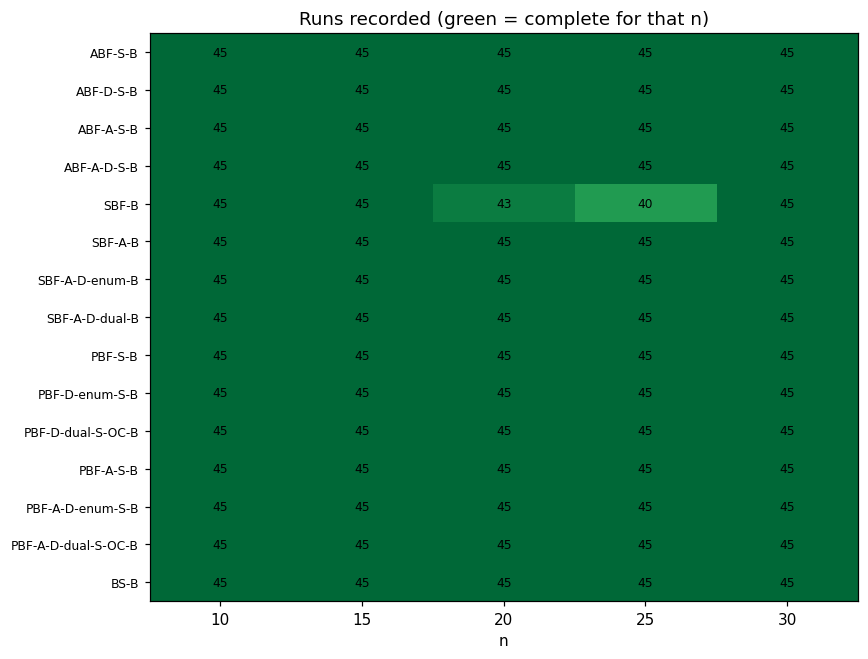

In [28]:
coverage_heatmap(df, over='n')

## 3. Choosing formulations

`select` filters by what a formulation *is* rather than by its label, so a
selection keeps working when a new modifier is added. Any column works as a
keyword, and scalars and lists are both accepted:

| keyword | meaning |
|---|---|
| `base` | `'ABF'`, `'SBF'`, `'PBF'`, `'BS'` |
| `extended` | `-A`, polyhedral approximation |
| `decomposition` | `-D`, Benders |
| `cut` | `'enum'`, `'dual'`, `'DE'`; `False` for none |
| `strengthen` | `-S`, DFJ strengthening |
| `opt_coeff` | `-OC`, optimised coefficients |
| `symmetry` | `-B`, symmetry breaking |

Every keyword is a filter you opt into, and they combine with AND, so each
one you add narrows the selection. **To keep both values of a modifier, leave
it out** -- omitting `decomposition` keeps the decomposed and the
non-decomposed variants alike. A list says the same thing explicitly, and
works on any keyword: `base=['ABF','SBF']`, `cut=['dual','enum']`,
`n=[20, 25, 30]`. For `cut`, `False` means no cut-type token, and it may
appear inside a list.

A selection that no single predicate describes is the union of two, which
`order_formulations` dedupes and re-sorts.

It returns labels in a stable base-then-modifier order, which is also the
order the colours follow. Pass an explicit list instead whenever that is
easier.

In [29]:
print('every formulation        :', formulations_in(df))
print()
print('PBF only                 :', select(df, base='PBF'))
print('extended, no decomposition:', select(df, extended=True, decomposition=False))
print('dual cuts                :', select(df, cut='dual'))
print('plain (no modifiers)     :', select(df, extended=False, decomposition=False,
                                           cut=False, opt_coeff=False))

every formulation        : ['ABF-S-B', 'ABF-D-S-B', 'ABF-A-S-B', 'ABF-A-D-S-B', 'SBF-B', 'SBF-A-B', 'SBF-A-D-enum-B', 'SBF-A-D-dual-B', 'PBF-S-B', 'PBF-D-enum-S-B', 'PBF-D-dual-S-OC-B', 'PBF-A-S-B', 'PBF-A-D-enum-S-B', 'PBF-A-D-dual-S-OC-B', 'BS-B']

PBF only                 : ['PBF-S-B', 'PBF-D-enum-S-B', 'PBF-D-dual-S-OC-B', 'PBF-A-S-B', 'PBF-A-D-enum-S-B', 'PBF-A-D-dual-S-OC-B']
extended, no decomposition: ['ABF-A-S-B', 'SBF-A-B', 'PBF-A-S-B']
dual cuts                : ['SBF-A-D-dual-B', 'PBF-D-dual-S-OC-B', 'PBF-A-D-dual-S-OC-B']
plain (no modifiers)     : ['ABF-S-B', 'SBF-B', 'PBF-S-B', 'BS-B']


In [30]:
# Keeping both values of a modifier: omit it, or list both.
print('PBF, -D and not  :', select(df, base='PBF'))
print('same, spelt out  :', select(df, base='PBF', decomposition=[True, False]))
print('PBF, -D only     :', select(df, base='PBF', decomposition=True))
print('dual cuts or none:', select(df, base='PBF', cut=['dual', False]))

# A union, for a set no single predicate describes.
print('ABF -D + PBF non--D:', order_formulations(
    select(df, base='ABF', decomposition=True)
    + select(df, base='PBF', decomposition=False)))

PBF, -D and not  : ['PBF-S-B', 'PBF-D-enum-S-B', 'PBF-D-dual-S-OC-B', 'PBF-A-S-B', 'PBF-A-D-enum-S-B', 'PBF-A-D-dual-S-OC-B']
same, spelt out  : ['PBF-S-B', 'PBF-D-enum-S-B', 'PBF-D-dual-S-OC-B', 'PBF-A-S-B', 'PBF-A-D-enum-S-B', 'PBF-A-D-dual-S-OC-B']
PBF, -D only     : ['PBF-D-enum-S-B', 'PBF-D-dual-S-OC-B', 'PBF-A-D-enum-S-B', 'PBF-A-D-dual-S-OC-B']
dual cuts or none: ['PBF-S-B', 'PBF-D-dual-S-OC-B', 'PBF-A-S-B', 'PBF-A-D-dual-S-OC-B']
ABF -D + PBF non--D: ['ABF-D-S-B', 'ABF-A-D-S-B', 'PBF-S-B', 'PBF-A-S-B']


In [31]:
# The selection every figure below uses.  Change this one line to re-aim the
# whole notebook.
FORMULATIONS = select(df, base=['ABF', 'PBF'], decomposition=True)

# Optional display names; leave as None to use the labels themselves.
LABELS = None

FORMULATIONS

['ABF-D-S-B',
 'ABF-A-D-S-B',
 'PBF-D-enum-S-B',
 'PBF-D-dual-S-OC-B',
 'PBF-A-D-enum-S-B',
 'PBF-A-D-dual-S-OC-B']

## 4. Performance profiles

The left half counts instances solved to optimality against runtime, the right
half continues with the unsolved ones ordered by final gap, so one step curve
carries a formulation's whole record. Both axes are read off the data.

Coverage that is not uniform raises a warning rather than silently comparing
different instance sets; pass `align=True` to restrict to the cells every
selected formulation ran.

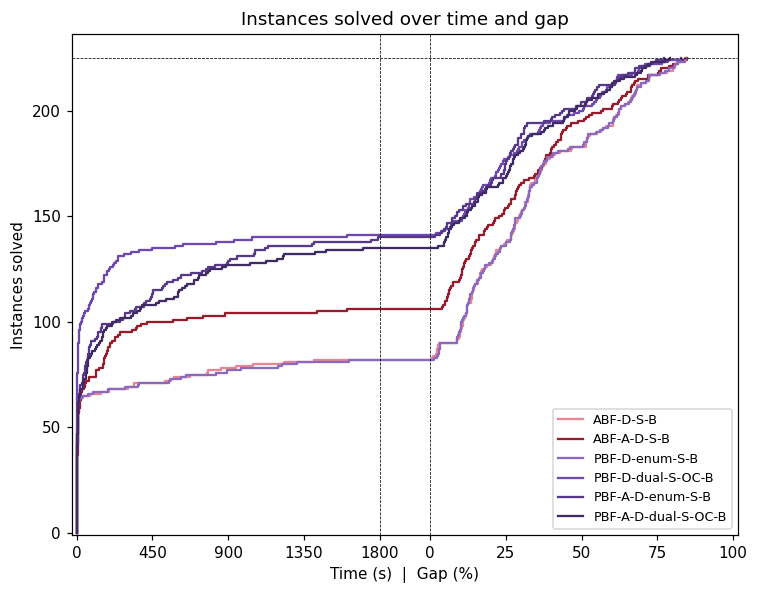

In [32]:
performance_profile(df, FORMULATIONS, labels=LABELS,
                    title='Instances solved over time and gap',
                    figsize=(7, 5.5))

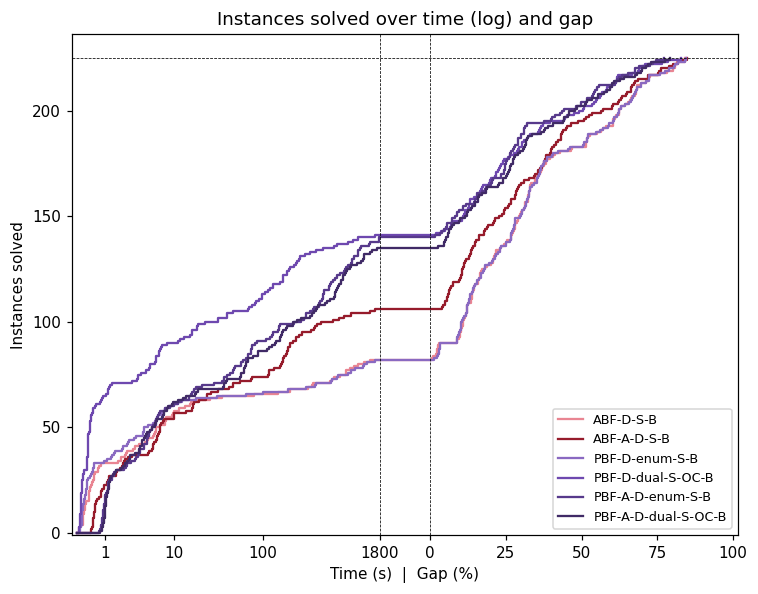

In [33]:
# With a 1800 s limit most runs finish in the first few percent of the axis.
# A log time scale usually reads far better; everything else is unchanged.
performance_profile(df, FORMULATIONS, labels=LABELS, time_scale='log',
                    title='Instances solved over time (log) and gap',
                    figsize=(7, 5.5))

### Faceting

`facet_by` takes any column -- `'n'`, `'r_mean'`, `'sigma'` -- or a list of
them for combinations. Panels are laid out automatically, so the
number of values does not matter. `share_scale=True` (the default) keeps one
time limit and gap ceiling across panels so they compare; turn it off to let
each panel use its own range.

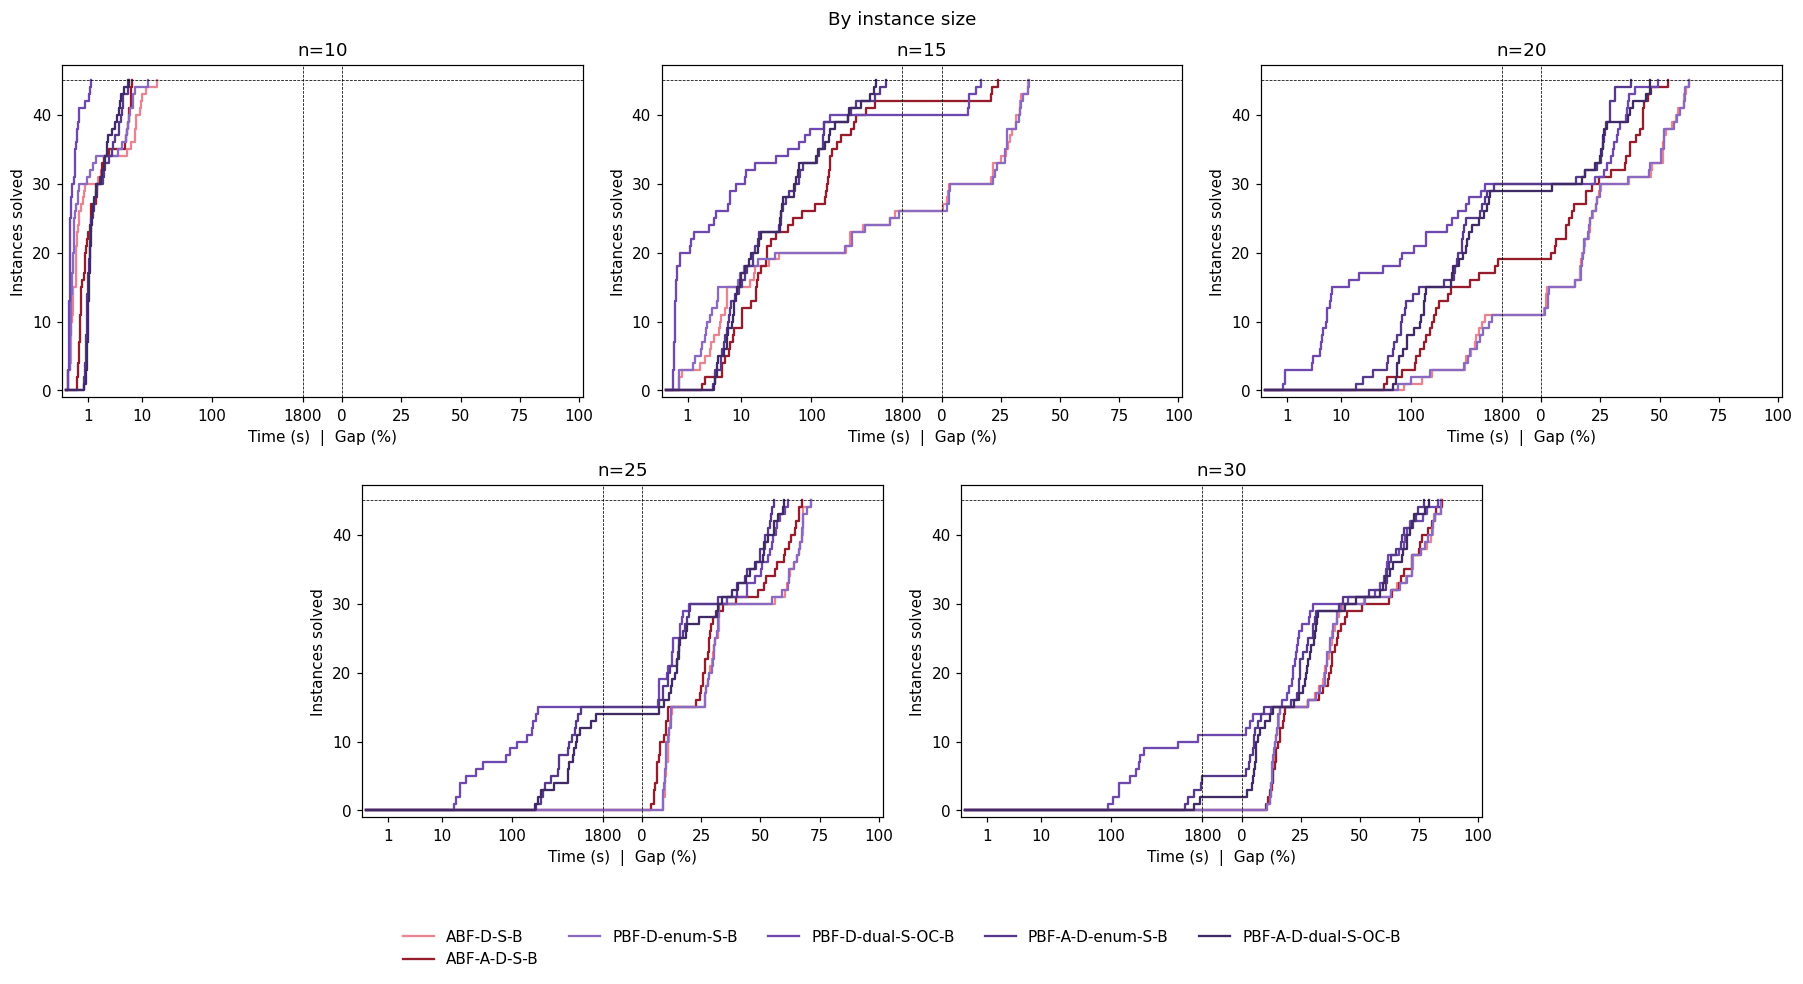

In [34]:
performance_profile(df, FORMULATIONS, labels=LABELS, facet_by='n',
                    time_scale='log', title='By instance size')

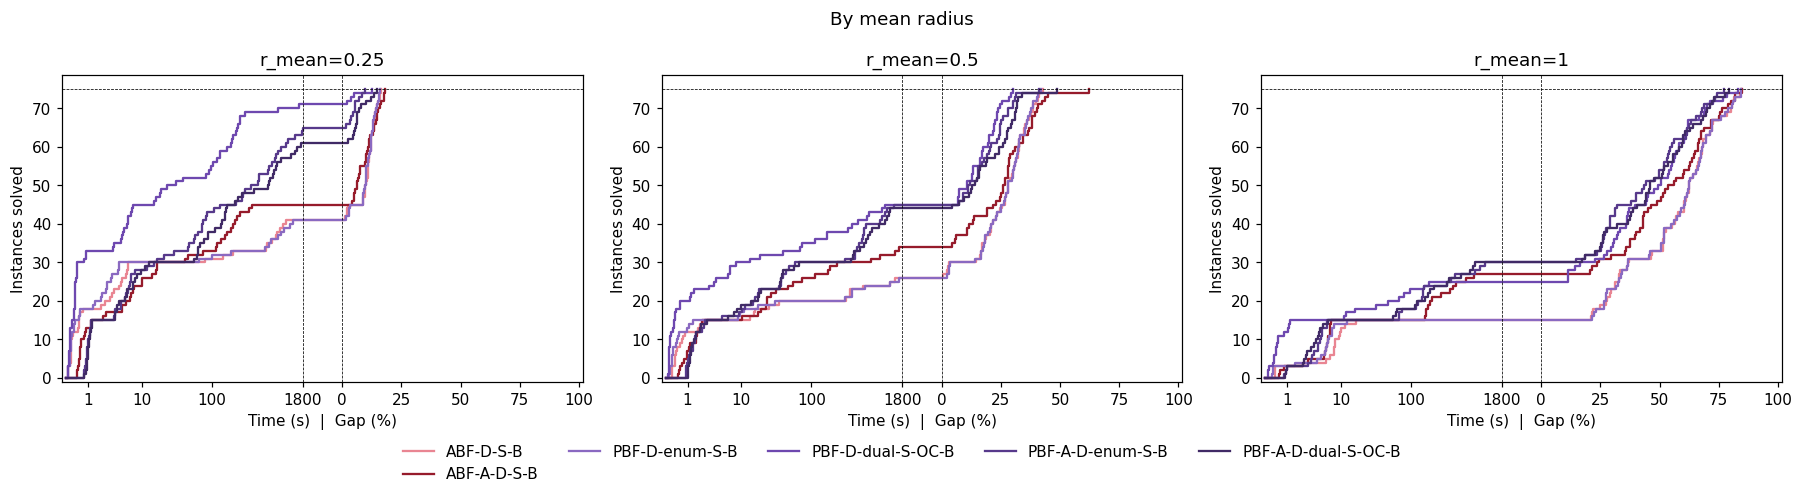

In [35]:
performance_profile(df, FORMULATIONS, labels=LABELS, facet_by='r_mean',
                    time_scale='log', title='By mean radius')

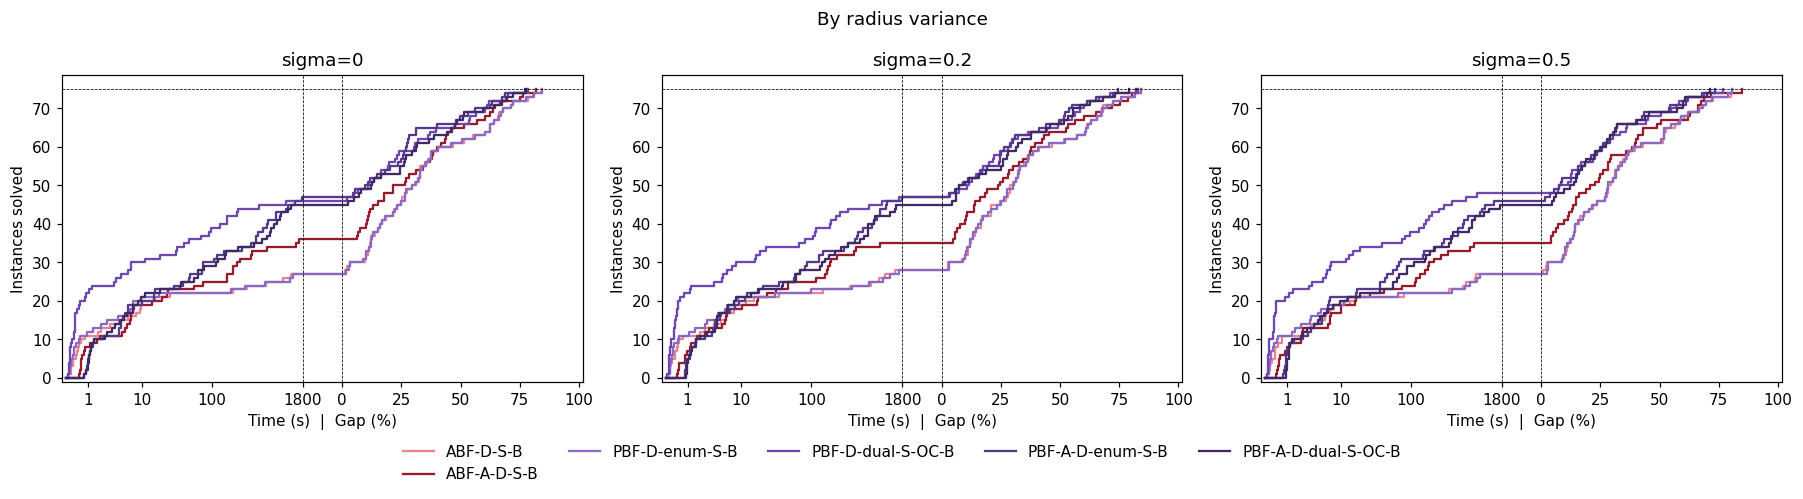

In [36]:
performance_profile(df, FORMULATIONS, labels=LABELS, facet_by='sigma',
                    time_scale='log', title='By radius variance')

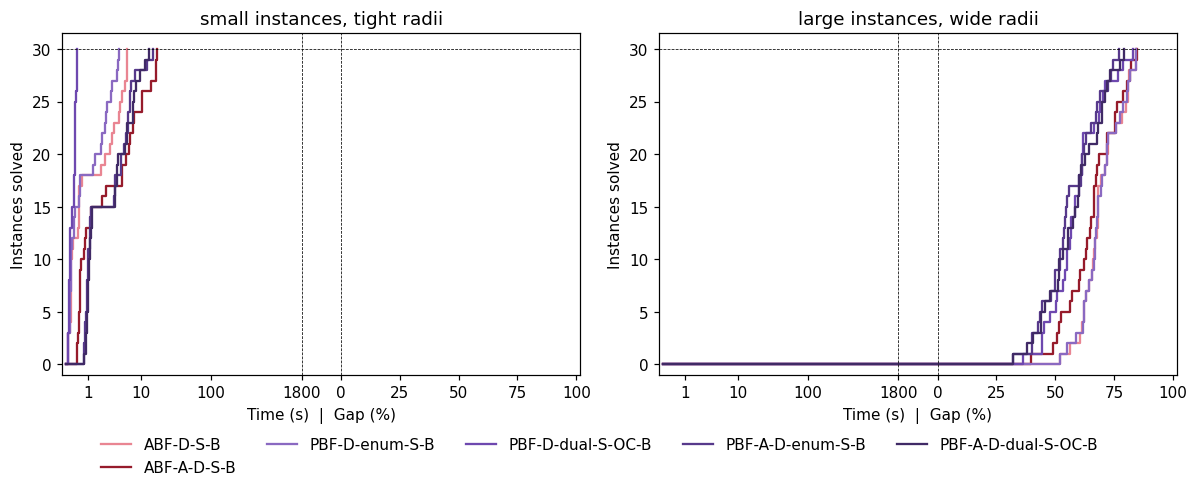

In [37]:
# Panels can also be named explicitly, with any select() filters behind each.
performance_profile(
    df, FORMULATIONS, labels=LABELS,
    facets={'small instances, tight radii': {'n': [10, 15], 'r_mean': 0.25},
            'large instances, wide radii':  {'n': [25, 30], 'r_mean': 1.0}},
    time_scale='log')

## 5. Summary tables

`metrics` picks the columns from the registry in `utils.results.METRICS`, and
`by` breaks the comparison down by any column. Add an entry to `METRICS` to
make a new column available everywhere.

Note that `Opt` counts runs that proved optimality *of their own model*: for
the approximate formulations (and for B&S) a discretisation gap remains, which
is why `Gap (%)` is reported over all runs and not only the unsolved ones.

In [38]:
print('available metrics:', list(METRICS))

summary_table(df, FORMULATIONS, labels=LABELS)

available metrics: ['Runs', 'Opt', 'Opt (%)', 'TimeOpt', 'TimeAll', 'Gap (%)', 'Gap NoOpt (%)', 'RootGap (%)', 'Cuts', 'DFJ Cuts', 'Nodes', 'SubFail']


,Formulation,Runs,Opt,TimeOpt,Gap (%),Gap NoOpt (%),Cuts
0,ABF-D-S-B,225,82,135.03,22.25,35.01,33448.25
1,ABF-A-D-S-B,225,106,115.06,18.30,34.59,115.83
2,PBF-D-enum-S-B,225,82,146.11,22.23,34.97,33299.42
3,PBF-D-dual-S-OC-B,225,141,80.44,12.89,34.54,1182.14
4,PBF-A-D-enum-S-B,225,140,224.95,12.35,32.70,142.08
5,PBF-A-D-dual-S-OC-B,225,135,217.13,13.42,33.55,98.61


In [39]:
summary_table(df, FORMULATIONS, labels=LABELS, by='n',
              metrics=('Runs', 'Opt', 'TimeOpt', 'Gap (%)', 'RootGap (%)',
                       'Nodes'))

,Formulation,n,Runs,Opt,TimeOpt,Gap (%),RootGap (%),Nodes
0,ABF-D-S-B,10,45,45,2.68,0.00,20.37,2511
1,ABF-D-S-B,15,45,26,165.84,9.91,31.92,147919
2,ABF-D-S-B,20,45,11,603.67,24.64,36.98,317209
3,ABF-D-S-B,25,45,0,-,35.20,41.15,409371
4,ABF-D-S-B,30,45,0,-,41.51,45.96,470012
5,ABF-A-D-S-B,10,45,45,2.19,-0.00,36.39,3889
6,ABF-A-D-S-B,15,45,42,117.59,1.45,44.69,203143
7,ABF-A-D-S-B,20,45,19,376.80,16.32,52.39,417329
8,ABF-A-D-S-B,25,45,0,-,31.28,57.28,306096
9,ABF-A-D-S-B,30,45,0,-,42.43,62.52,182660


In [40]:
# numeric=True returns raw numbers, for exporting or further arithmetic.
wide = summary_table(df, FORMULATIONS, by='n', numeric=True,
                     metrics=('Opt',), warn=False)
wide.pivot(index='Formulation', columns='n', values='Opt')

n,10,15,20,25,30
Formulation,,,,,
ABF-A-D-S-B,45.0,42.0,19.0,0.0,0.0
ABF-D-S-B,45.0,26.0,11.0,0.0,0.0
PBF-A-D-dual-S-OC-B,45.0,45.0,29.0,14.0,2.0
PBF-A-D-enum-S-B,45.0,45.0,30.0,15.0,5.0
PBF-D-dual-S-OC-B,45.0,40.0,30.0,15.0,11.0
PBF-D-enum-S-B,45.0,26.0,11.0,0.0,0.0


## 6. Head to head

Points are paired on `(n, r_min, r_max, Instance)`, so only cells both
formulations ran are drawn and every point compares the same instance.
`color_by` and `marker_by` accept any column.

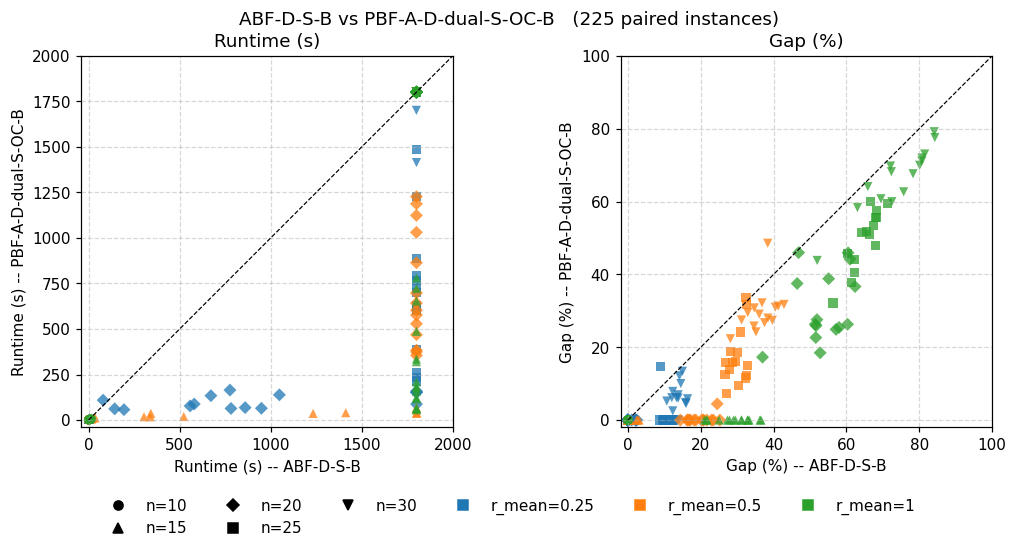

In [41]:
X, Y = FORMULATIONS[0], FORMULATIONS[-1]
pairwise_scatter(df, X, Y, metrics=('Time', 'GapPct'),
                 color_by='r_mean', marker_by='n')

In [42]:
# The underlying paired frame, for picking out individual instances.
paired = pairwise_table(df, X, Y, metrics=('Time', 'GapPct'))
paired['Time_delta'] = paired['Time_y'] - paired['Time_x']
paired.sort_values('Time_delta').head(10)

,n,r_min,r_max,Instance,Time_x,GapPct_x,Solved_x,Status_x,Time_y,GapPct_y,Solved_y,Status_y,Time_delta
73,15,0.500,0.500,3,1801.203995,3.073395,False,Time_Limit,37.146752,-0.000008,True,Optimal,-1764.057243
63,15,0.400,0.600,3,1801.145970,2.656578,False,Time_Limit,38.821461,-0.000046,True,Optimal,-1762.324509
68,15,0.250,0.750,3,1800.332321,2.380611,False,Time_Limit,56.540919,-0.000008,True,Optimal,-1743.791402
84,15,0.500,1.500,4,1800.032114,21.713755,False,Time_Limit,56.905930,0.000070,True,Optimal,-1743.126185
79,15,0.800,1.200,4,1800.787244,20.962726,False,Time_Limit,62.049778,0.000079,True,Optimal,-1738.737466
89,15,1.000,1.000,4,1800.386529,25.019510,False,Time_Limit,65.067002,0.000008,True,Optimal,-1735.319528
67,15,0.250,0.750,2,1800.018085,0.669657,False,Time_Limit,67.578218,0.000032,True,Optimal,-1732.439866
97,20,0.125,0.375,2,1800.691150,2.145224,False,Time_Limit,87.600450,-0.000069,True,Optimal,-1713.090700
85,15,1.000,1.000,0,1800.027770,27.315065,False,Time_Limit,115.626749,0.000122,True,Optimal,-1684.401021
86,15,1.000,1.000,1,1800.013509,21.520073,False,Time_Limit,123.243696,0.000073,True,Optimal,-1676.769813


## 7. Scaling

Any aggregate of any metric against any column. `agg='solved'` counts
instances solved to optimality.

A line **breaks** wherever a formulation has nothing to aggregate rather than
being carried across the gap, and a warning names the missing points. With
`solved_only=True` that is the common case: a formulation that proved nothing
optimal at some size has no runtime to average there, so its line stops.

That also leaves the surviving means resting on very different numbers of
runs: at n=30 the means below are over 2, 5 and 11 instances. A formulation
can look fastest there simply because it solved only the easy subset. Marker
area tracks the size of the sample behind each point, so a thin mean shrinks
away; the plot is unchanged when every point rests on the same number of
runs. `min_count=` drops the thin ones outright, and `agg='solved'` plots the
counts themselves.

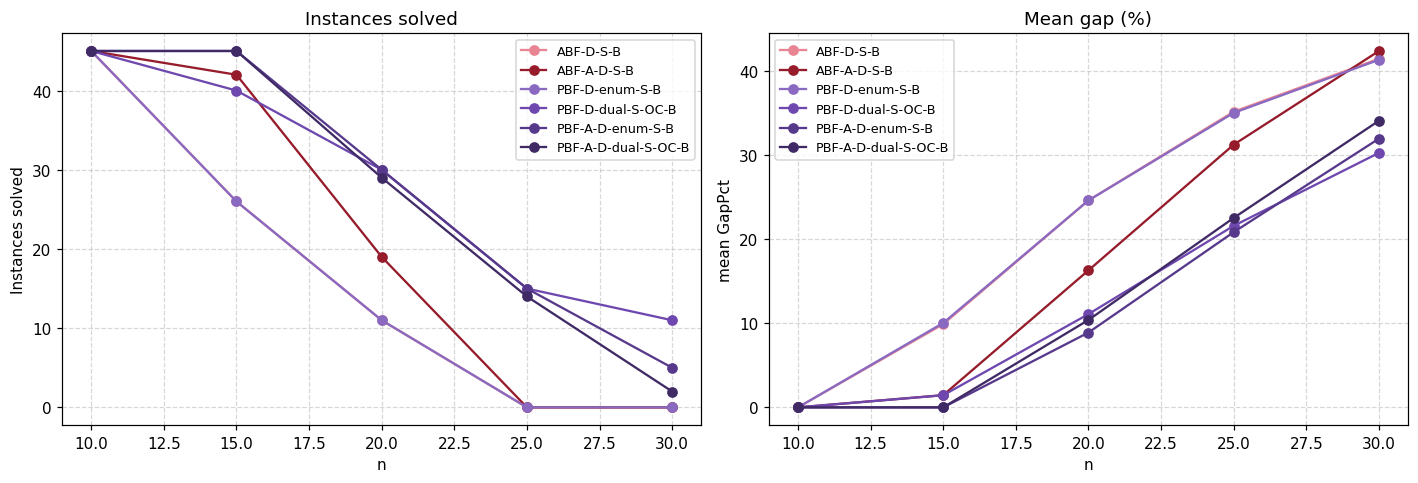

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
scaling_plot(df, FORMULATIONS, labels=LABELS, agg='solved', over='n',
             ax=axes[0], title='Instances solved')
scaling_plot(df, FORMULATIONS, labels=LABELS, metric='GapPct', agg='mean',
             over='n', ax=axes[1], title='Mean gap (%)')
fig.tight_layout()

c:\Users\daray\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\interactiveshell.py:3460: UserWarning: line(s) stop short because a formulation solved nothing there: ABF-D-S-B at n=25, 30; ABF-A-D-S-B at n=25, 30; PBF-D-enum-S-B at n=25, 30.  Those points are gaps, not zeros.
  exec(code_obj, self.user_global_ns, self.user_ns)


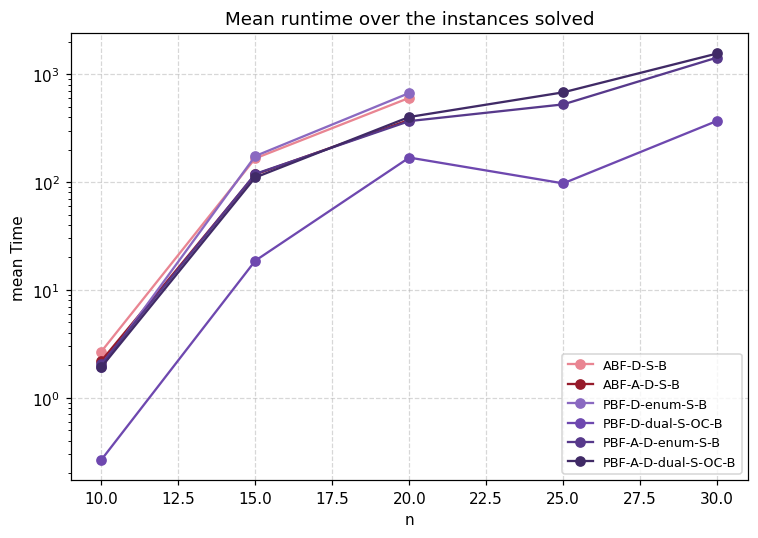

In [44]:
scaling_plot(df, FORMULATIONS, labels=LABELS, metric='Time', agg='mean',
             over='n', solved_only=True, logy=True,
             title='Mean runtime over the instances solved')

c:\Users\daray\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\interactiveshell.py:3460: UserWarning: line(s) stop short because a formulation solved nothing there: ABF-D-S-B at n=25, 30; ABF-A-D-S-B at n=25, 30; PBF-D-enum-S-B at n=25, 30; PBF-A-D-dual-S-OC-B at n=30.  Those points are gaps, not zeros.
  exec(code_obj, self.user_global_ns, self.user_ns)


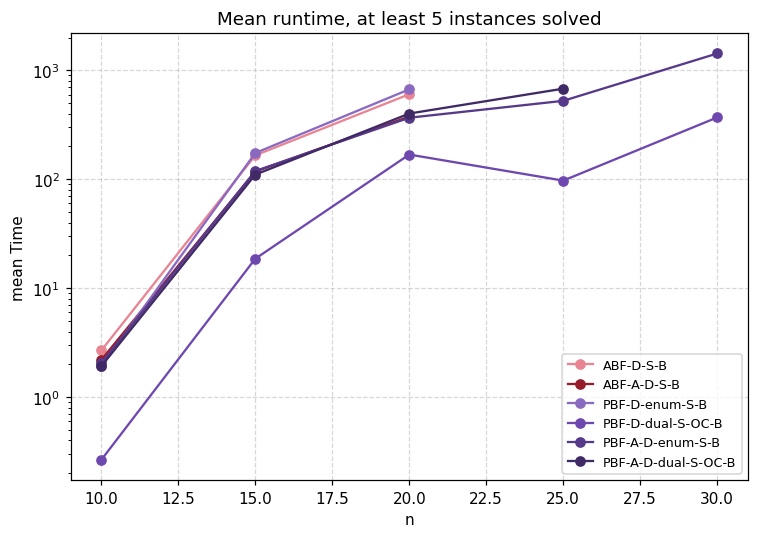

In [45]:
# Same plot, but only where at least 5 instances back the mean.
scaling_plot(df, FORMULATIONS, labels=LABELS, metric='Time', agg='mean',
             over='n', solved_only=True, logy=True, min_count=5,
             title='Mean runtime, at least 5 instances solved')

## 8. Saving

Every plotting function takes `filename=` and writes a transparent 300 dpi
figure. Tables are ordinary DataFrames, so `.to_csv` and `.to_latex` apply.

In [46]:
from pathlib import Path

OUT = Path('Results/figures')
OUT.mkdir(parents=True, exist_ok=True)

performance_profile(df, FORMULATIONS, labels=LABELS, facet_by='n',
                    time_scale='log', filename=OUT / 'profile_by_n.png',
                    show=False)
plt.close('all')

table = summary_table(df, FORMULATIONS, labels=LABELS)
table.to_csv(OUT / 'summary.csv', index=False)
print(table.to_latex(index=False))

\begin{tabular}{lllllll}
\toprule
Formulation & Runs & Opt & TimeOpt & Gap (%) & Gap NoOpt (%) & Cuts \\
\midrule
ABF-D-S-B & 225 & 82 & 135.03 & 22.25 & 35.01 & 33448.25 \\
ABF-A-D-S-B & 225 & 106 & 115.06 & 18.30 & 34.59 & 115.83 \\
PBF-D-enum-S-B & 225 & 82 & 146.11 & 22.23 & 34.97 & 33299.42 \\
PBF-D-dual-S-OC-B & 225 & 141 & 80.44 & 12.89 & 34.54 & 1182.14 \\
PBF-A-D-enum-S-B & 225 & 140 & 224.95 & 12.35 & 32.70 & 142.08 \\
PBF-A-D-dual-S-OC-B & 225 & 135 & 217.13 & 13.42 & 33.55 & 98.61 \\
\bottomrule
\end{tabular}

